In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt

from epigenetic_clocks import Hannum

In [2]:
# ── Load your real data ───────────────────────────────────────────────
with open('/work/gr-fe/bryan/EpiHydra/data/02_processed/GSE40279/methylation.pkl', 'rb') as file:
    data = pickle.load(file)

# Beta value matrix (rows = CpGs, columns = samples)
methylation = data['CpG']

# Chronological ages, indexed by sample ID (used later for evaluation)
chron_ages = data['meta'].set_index('ID')['age']

# ── Initialise the Horvath clock ────────────────────────────────────────
# Coefficients come from Horvath 2013 supplementary AdditionalFile3.csv
clock = Hannum(coefficients_path="/work/gr-fe/bryan/EpiHydra/data/03_final/Hannum/hannum.csv")
clock.coefficients.head()

Loaded 71 CpG coefficients.


/tmp/4787841/ipykernel_2889321/1731428267.py:13: UserWarning: Hannum intercept is set to 0.0 (the default). This is almost certainly incorrect and will bias every prediction. Supply the correct value from the paper's supplementary materials.
  clock = Hannum(coefficients_path="/work/gr-fe/bryan/EpiHydra/data/03_final/Hannum/hannum.csv")


,Marker,Chrom,Pos,Genes,CpG Island,Coefficient
0,cg20822990,1,17338766,"ATP13A2,SDHB",No,-15.70
1,cg22512670,1,26855765,RPS6KA1,No,1.05
2,cg25410668,1,28241577,"RPA2,SMPDL3B",No,3.87
3,cg04400972,1,117665053,"TRIM45,TTF2",Yes,9.62
4,cg16054275,1,169556022,"F5,SELP",No,-11.10


In [4]:
results = clock.predict(methylation)
results 

,DNAmAge
SampleID,
GSM989827,67.134750
GSM989828,86.167865
GSM989829,68.953058
GSM989830,68.895559
GSM989831,67.932521
...,...
GSM990623,79.834723
GSM990624,76.036389
GSM990625,67.845801


In [5]:
comparison = results.join(chron_ages.rename("ChronAge"))
comparison['DNAmAge'] = comparison['DNAmAge']
comparison["AgeAcceleration"] = comparison["DNAmAge"] - comparison["ChronAge"]
comparison

,DNAmAge,ChronAge,AgeAcceleration
SampleID,,,
GSM989827,67.134750,67.0,0.134750
GSM989828,86.167865,89.0,-2.832135
GSM989829,68.953058,66.0,2.953058
GSM989830,68.895559,64.0,4.895559
GSM989831,67.932521,62.0,5.932521
...,...,...,...
GSM990623,79.834723,78.0,1.834723
GSM990624,76.036389,71.0,5.036389
GSM990625,67.845801,68.0,-0.154199


In [45]:
metrics = clock.compute_metrics(
    comparison["ChronAge"],
    comparison["DNAmAge"],
    age_accel_method="difference",
)
metrics

,"Cor(Age, DNAmAge)",Median Absolute Error (years),Median Age Acceleration
0,0.9461,5.1292,4.907


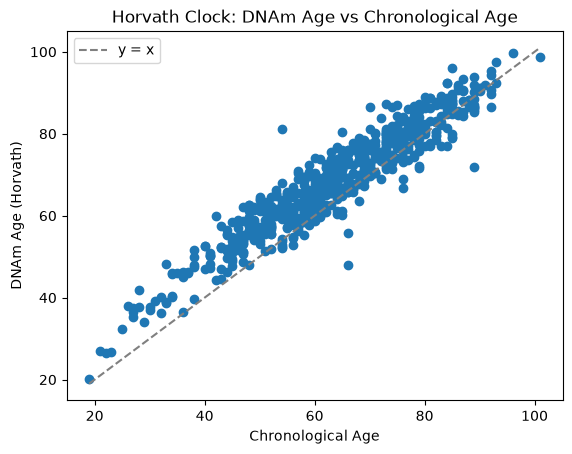

In [46]:
plt.scatter(comparison["ChronAge"], comparison["DNAmAge"])
plt.xlabel("Chronological Age")
plt.ylabel("DNAm Age (Horvath)")
plt.plot(
    [comparison["ChronAge"].min(), comparison["ChronAge"].max()],
    [comparison["ChronAge"].min(), comparison["ChronAge"].max()],
    linestyle="--", color="grey", label="y = x",
)
plt.legend()
plt.title("Horvath Clock: DNAm Age vs Chronological Age")
plt.show()

In [64]:
paper_results = {
    "Cor(Age, DNAmAge)" : 0.96, 
    "Median Absolute Error (years)" : 3.9 , 
    "Median Age Acceleration" : np.nan
}

In [65]:
metrics

,"Cor(Age, DNAmAge)",Median Absolute Error (years),Median Age Acceleration
0,0.9461,5.1292,4.907


In [66]:
validation = clock.validate(
    metrics,
    pd.DataFrame(paper_results , index=[0]),
    dataset_name=None,
)
validation


  Clock Validation — None
                          Yours  Paper  Abs. Diff  Tolerance  Status
Metric                                                              
Cor(Age, DNAmAge)        0.9461   0.96     0.0139       0.05  ✓ Pass
Median Absolute Error    5.1292   3.90     1.2292       0.50  ✗ Fail
Median Age Acceleration  4.9070    NaN        NaN       0.50  ✗ Fail
  ✗ Outside tolerance: Median Absolute Error, Median Age Acceleration
  Check: CpG preprocessing, age transformation,
         sample filtering, or training CpG selection.



,Yours,Paper,Abs. Diff,Tolerance,Status
Metric,,,,,
"Cor(Age, DNAmAge)",0.9461,0.96,0.0139,0.05,✓ Pass
Median Absolute Error,5.1292,3.90,1.2292,0.50,✗ Fail
Median Age Acceleration,4.9070,NaN,NaN,0.50,✗ Fail


In [54]:
pd.DataFrame(paper_results , index=[0])

,"Cor(Age,m.age(Train.CpGs))","Median error (Age, m.age(Train.CpGs))",Median AgeAcceleration(Train.CpGs)
0,0.96,3.9,NaN
